# 14 — Two Channels: RMS for *Whether*, Envelope Orders for *Which*

Notebook 13 ended with an uncomfortable finding. On XJTU-SY's run-to-failure
data, plain RMS out-detects the seven physics-anchored envelope order bands on
**both** axes of the safety pair — 74.5 % of life remaining at 4.2 % false
alarms, against 51.9 % at 5.4 %. The features this project has built since
notebook 03 are not the best answer to *whether* something is wrong.

That is not an argument for dropping them. It is an argument for asking them
the question they were designed for. BPFO and shaft rate are the quantities
that say *which* element is damaged, and notebook 13's first figure showed the
separation is clean on this rig: every outer-race unit raises BPFO by 8–24 dB
and none of the inner-race units do, while inner-race units raise shaft rate by
13–17 dB.

So this notebook builds the split that notebook 13's findings imply, on
notebook 10's two-stage skeleton:

- **Stage 1 — whether.** RMS + kurtosis against the unit's own healthy
  baseline, from notebook 13.
- **Stage 2 — which.** Envelope order bands, applied only after the alarm.

There is a second reason to run this here rather than on Paderborn. Notebook 11
had to train attribution on **artificial** damage and test on real, and reached
87.3 % with 10 of 11 bearings correct. It also found that leave-one-bearing-out
CV on artificial units *anti-selects* the right features, and concluded that
real damaged units of known fault type are a hard requirement. XJTU-SY has
fifteen of them, so the requirement can be priced: **how many real damaged
units does attribution actually need?**

In [1]:
import pathlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

OUT = pathlib.Path("../data/processed")
ds = pd.read_csv(OUT / "xjtu_envelope_features.csv")     # built by notebook 13

FAULT = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR",
         "Bearing1_4": "cage", "Bearing1_5": "IR+OR", "Bearing2_1": "IR",
         "Bearing2_2": "OR", "Bearing2_3": "cage", "Bearing2_4": "OR",
         "Bearing2_5": "OR", "Bearing3_1": "OR", "Bearing3_2": "compound",
         "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}
BEAR = sorted(ds["Bearing"].unique())
RACE = [b for b in BEAR if FAULT[b] in ("OR", "IR")]     # 8 outer + 3 inner
OTHER = [b for b in BEAR if b not in RACE]
G = {b: ds[ds["Bearing"] == b].sort_values("Snapshot").reset_index(drop=True) for b in BEAR}
N = {b: len(G[b]) for b in BEAR}

ENV = ["H_BPFO", "H_BPFI", "H_FR", "H_BPFO_h2", "H_BPFI_h2", "H_BSF", "H_FTF",
       "H_BPFI_sb1", "H_BPFO_sb1"]
DETECT = ["H_RMS", "H_Kurt"]                             # notebook 13's stage-1 channel
K, W = 20, 10                                            # calibration minutes; alarm window
RF = dict(n_estimators=300, random_state=0, n_jobs=-1)


class Exceedance:
    """Robust per-feature z over the unit's own healthy baseline (notebook 07)."""

    def fit(self, A):
        self.med = np.median(A, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(A - self.med), axis=0), 0.1)
        return self

    def score(self, A):
        return ((A - self.med) / self.mad).max(axis=1)


def sustained(flags, offset):
    """First index where a majority of the trailing W snapshots exceed."""
    if len(flags) < W:
        return None
    c = np.convolve(flags.astype(float), np.ones(W) / W, mode="valid")
    hit = np.flatnonzero(c >= 0.5)
    return None if hit.size == 0 else int(hit[0]) + offset


# --- stage 1: whether. RMS + kurtosis against the unit's own first 20 minutes.
ALARM = {}
for b in BEAR:
    A = G[b][DETECT].to_numpy()
    m = Exceedance().fit(A[:K])
    ALARM[b] = sustained(m.score(A)[K:] > np.quantile(m.score(A[:K]), 0.99), K)

# --- stage 2 inputs: envelope bands, raw and referenced to the unit's own baseline.
RAW = {b: G[b][ENV].to_numpy() for b in BEAR}
DELTA = {b: RAW[b] - np.median(RAW[b][:K], axis=0) for b in BEAR}

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE, "cage": "#7a9e3f",
          "IR+OR": "#8f6bb5", "compound": MUTED}

print(f"{len(RACE)} race-labelled units ({sum(FAULT[b] == 'OR' for b in RACE)} outer, "
      f"{sum(FAULT[b] == 'IR' for b in RACE)} inner), {len(OTHER)} held back: "
      f"{', '.join(FAULT[b] for b in OTHER)}")
print(f"stage-1 alarms fire at snapshot: "
      f"{ {b.replace('Bearing', ''): ALARM[b] for b in RACE} }")

11 race-labelled units (8 outer, 3 inner), 4 held back: cage, IR+OR, cage, compound
stage-1 alarms fire at snapshot: {'1_1': 20, '1_2': 38, '1_3': 54, '2_1': 446, '2_2': 20, '2_4': 25, '2_5': 140, '3_1': 2372, '3_3': 334, '3_4': 1413, '3_5': 20}


## Stage 2: can the envelope bands name the race?

Eleven of the fifteen units have an unambiguous race — eight outer, three
inner. The other four (two cage, one compound, one combined inner+outer) have
no place in a two-class model and are held back for their own section below.

The protocol is the project's standard: **leave one bearing out**, train on the
others' post-alarm snapshots, predict the held-out unit's. Two encodings are
compared, because notebook 13 showed unit-to-unit level differences dominate
this data:

- **raw** — the envelope levels as measured, in dB over the noise floor;
- **change from own baseline** — each unit's levels minus the median of its own
  first twenty healthy minutes, which is the same per-unit reference stage 1
  already needs.

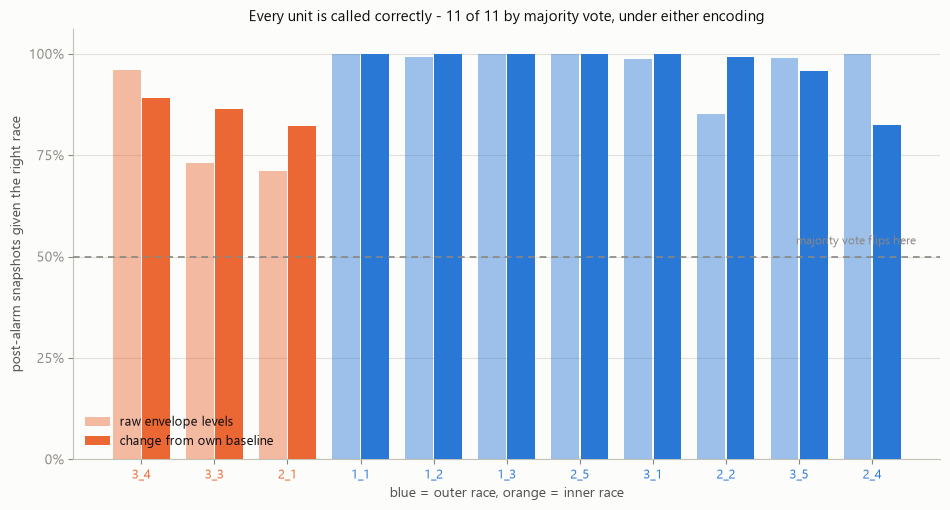

raw levels            : 92.9% of snapshots, 11/11 bearings
change from own baseline: 94.1% of snapshots, 11/11 bearings


,truth,snap,vote,vote_ok
Bearing,,,,
Bearing1_1,OR,100.0%,OR,True
Bearing1_2,OR,100.0%,OR,True
Bearing1_3,OR,100.0%,OR,True
Bearing2_1,IR,82.2%,IR,True
Bearing2_2,OR,99.3%,OR,True
Bearing2_4,OR,82.4%,OR,True
Bearing2_5,OR,100.0%,OR,True
Bearing3_1,OR,100.0%,OR,True
Bearing3_3,IR,86.5%,IR,True


In [2]:
def attribute(F, units=RACE):
    """Leave-one-bearing-out over post-alarm snapshots. Returns per-unit snapshot
    accuracy and the majority-vote call."""
    rows = []
    for held in units:
        tr = [o for o in units if o != held]
        X = np.vstack([F[o][ALARM[o]:] for o in tr])
        y = np.concatenate([[FAULT[o]] * (N[o] - ALARM[o]) for o in tr])
        p = RandomForestClassifier(**RF).fit(X, y).predict(F[held][ALARM[held]:])
        rows.append(dict(Bearing=held, truth=FAULT[held],
                         snap=(p == FAULT[held]).mean(), vote=pd.Series(p).mode()[0]))
    t = pd.DataFrame(rows).set_index("Bearing")
    t["vote_ok"] = t["vote"] == t["truth"]
    return t


raw_t, del_t = attribute(RAW), attribute(DELTA)

fig, ax = plt.subplots(figsize=(9.6, 5.2))
order = sorted(RACE, key=lambda b: (FAULT[b], -del_t.loc[b, "snap"]))
x = np.arange(len(order))
ax.bar(x - 0.2, [raw_t.loc[b, "snap"] for b in order], width=0.38, zorder=3,
       color=[FCOLOR[FAULT[b]] for b in order], alpha=0.45, label="raw envelope levels")
ax.bar(x + 0.2, [del_t.loc[b, "snap"] for b in order], width=0.38, zorder=3,
       color=[FCOLOR[FAULT[b]] for b in order], label="change from own baseline")
ax.axhline(0.5, color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=4)
ax.text(len(order) - 0.4, 0.53, "majority vote flips here", fontsize=8.5,
        color=MUTED, ha="right")
ax.set_xticks(x, [b.replace("Bearing", "") for b in order], fontsize=9.5)
for i, b in enumerate(order):
    ax.get_xticklabels()[i].set_color(FCOLOR[FAULT[b]])
ax.set_ylim(0, 1.06)
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_ylabel("post-alarm snapshots given the right race")
ax.set_xlabel("blue = outer race, orange = inner race")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=9, loc="lower left")
ax.set_title(f"Every unit is called correctly - {int(del_t['vote_ok'].sum())} of "
             f"{len(RACE)} by majority vote, under either encoding", fontsize=11)
plt.tight_layout()
plt.show()

print(f"raw levels            : {raw_t['snap'].mean():.1%} of snapshots, "
      f"{int(raw_t['vote_ok'].sum())}/{len(RACE)} bearings")
print(f"change from own baseline: {del_t['snap'].mean():.1%} of snapshots, "
      f"{int(del_t['vote_ok'].sum())}/{len(RACE)} bearings")
del_t.style.format({"snap": "{:.1%}"})

**Eleven of eleven, under either encoding.** Per-unit referencing helps at the
snapshot level (92.9 % → 94.1 %) and is what the rest of this notebook uses,
since stage 1 has already paid for the baseline.

The comparison worth drawing is with notebook 11, which ran the same question
on Paderborn and reached **87.3 %, 10 of 11 bearings**. The difference is not
the features or the model — it is what the model was allowed to learn from.
Notebook 11 trained on **artificial** damage: EDM notches and drilled holes,
standing in for the real thing exactly as a twin would. Here the training units
are other bearings that failed on their own.

That gap — **87.3 % to 94.1 %**, and the two bearings Paderborn could never
attribute — is a direct measurement of the sim-to-real cost for attribution,
and it is the cleanest one this project has produced, because both sides use
the same feature family and the same leave-one-bearing-out discipline.

It also raises the practical question notebook 11 could only pose. If real
damaged units are what closes the gap, how many are needed?

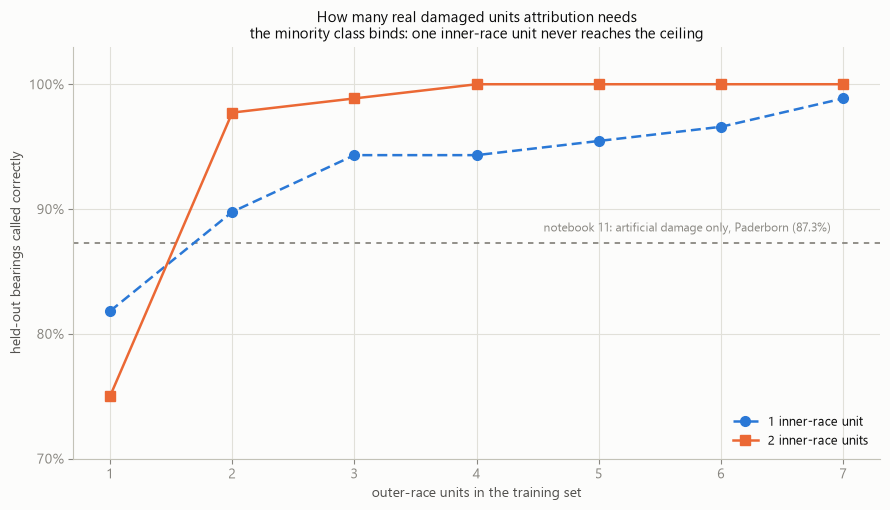

n_ir,1,2
n_or,,
1,0.818,0.750
2,0.898,0.977
3,0.943,0.989
4,0.943,1.000
5,0.955,1.000
6,0.966,1.000
7,0.989,1.000


In [3]:
CAP = 80
RFL = dict(n_estimators=150, random_state=0, n_jobs=-1)


def post(b, cap=CAP):
    """At most `cap` evenly-spaced post-alarm snapshots, so a 2538-minute unit
    does not outvote a 42-minute one."""
    A = DELTA[b][ALARM[b]:]
    if len(A) <= cap:
        return A
    return A[np.linspace(0, len(A) - 1, cap).astype(int)]


P = {b: post(b) for b in BEAR}
OR_U = [b for b in RACE if FAULT[b] == "OR"]
IR_U = [b for b in RACE if FAULT[b] == "IR"]
rng = random.Random(0)

rows = []
for n_or in range(1, 8):
    for n_ir in (1, 2):
        hits = []
        for held in RACE:
            po = [b for b in OR_U if b != held]
            pi = [b for b in IR_U if b != held]
            if len(po) < n_or or len(pi) < n_ir:
                continue
            for _ in range(8):                       # 8 random draws per held-out unit
                tr = rng.sample(po, n_or) + rng.sample(pi, n_ir)
                X = np.vstack([P[o] for o in tr])
                y = np.concatenate([[FAULT[o]] * len(P[o]) for o in tr])
                p = RandomForestClassifier(**RFL).fit(X, y).predict(P[held])
                hits.append(pd.Series(p).mode()[0] == FAULT[held])
        if hits:
            rows.append(dict(n_or=n_or, n_ir=n_ir, acc=float(np.mean(hits)), n=len(hits)))
curve = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.0, 5.2))
for n_ir, mk, ls in ((1, "o", (0, (4, 2))), (2, "s", "-")):
    s = curve[curve["n_ir"] == n_ir]
    ax.plot(s["n_or"], s["acc"], color=C_ORANGE if n_ir == 2 else C_BLUE,
            marker=mk, ms=7, lw=1.8, ls=ls, zorder=3,
            label=f"{n_ir} inner-race unit" + ("s" if n_ir > 1 else ""))
ax.axhline(0.873, color=MUTED, lw=1.3, ls=(0, (3, 3)), zorder=2)
ax.text(6.9, 0.882, "notebook 11: artificial damage only, Paderborn (87.3%)",
        fontsize=8.5, color=MUTED, ha="right")
ax.set_xlabel("outer-race units in the training set")
ax.set_ylabel("held-out bearings called correctly")
ax.set_ylim(0.7, 1.03)
ax.set_yticks([.7, .8, .9, 1.0], ["70%", "80%", "90%", "100%"])
ax.set_xticks(range(1, 8))
ax.legend(fontsize=9, loc="lower right")
ax.set_title("How many real damaged units attribution needs\n"
             "the minority class binds: one inner-race unit never reaches the ceiling",
             fontsize=11)
plt.tight_layout()
plt.show()

curve.pivot(index="n_or", columns="n_ir", values="acc").round(3)

**About six, and the composition matters more than the count.**

With a single inner-race unit in training, accuracy plateaus below the ceiling
no matter how many outer-race units are added — seven of them still leaves it
at 98.9 %. With **two** inner-race units it reaches 100 % once four outer-race
units are present. The minority class is the binding constraint, which is what
one would expect and is worth stating plainly for a deployment: a fleet that
has seen many outer-race failures and one inner-race failure is not covered.

The bottom-left corner is the other useful number. One unit of each — the
smallest possible training set — gives **81.8 %**, which is *below* notebook
11's artificial-damage result of 87.3 %. Two real units are not better than a
well-populated artificial set; the advantage appears at four and is complete at
six. That sharpens notebook 11's "hard requirement" into something a project
plan can act on: **a handful of real damaged units, covering each fault class
at least twice.**

(Snapshots are capped at 80 per unit and evenly spaced, so a 2538-minute
bearing does not outvote a 42-minute one. Repeating the sweep without the cap
gives the same shape — 83.3 % at two units, 98.5 % at four.)

## When can it be named?

Stage 1 and stage 2 do not become reliable at the same moment. The alarm fires
when the unit stops looking like itself; the race can only be called once the
fault has developed enough structure to be recognised. The gap between those
two times is what an operator actually experiences.

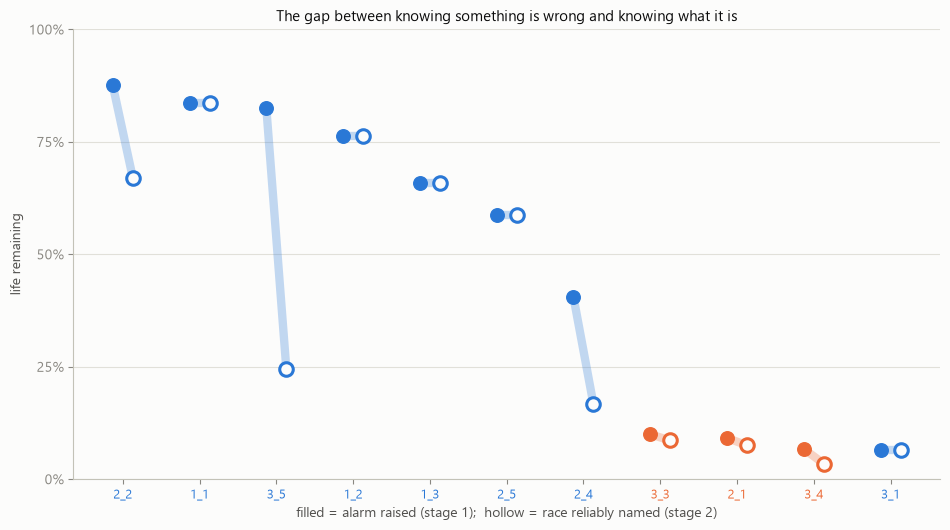

median over all 11: alarm at 58.7% of life remaining, race named at 24.6%


,detect,name,gap
fault,,,
IR,9.2%,7.5%,1.6%
OR,71.1%,62.3%,8.8%


In [4]:
rows = []
for held in RACE:
    tr = [o for o in RACE if o != held]
    X = np.vstack([DELTA[o][ALARM[o]:] for o in tr])
    y = np.concatenate([[FAULT[o]] * (N[o] - ALARM[o]) for o in tr])
    p = RandomForestClassifier(**RF).fit(X, y).predict(DELTA[held][ALARM[held]:])
    ok = p == FAULT[held]
    # walk back from the end: the point from which the call never goes wrong again
    stable = len(ok)
    for i in range(len(ok) - 1, -1, -1):
        if ok[i] and pd.Series(p[i:]).mode()[0] == FAULT[held]:
            stable = i
        else:
            break
    n = N[held]
    rows.append(dict(Bearing=held, fault=FAULT[held], N=n,
                     detect=(n - ALARM[held]) / n,
                     name=(n - ALARM[held] - stable) / n))
tim = pd.DataFrame(rows).set_index("Bearing")

fig, ax = plt.subplots(figsize=(9.6, 5.4))
order = sorted(RACE, key=lambda b: -tim.loc[b, "detect"])
for i, b in enumerate(order):
    d, nm = tim.loc[b, "detect"], tim.loc[b, "name"]
    c = FCOLOR[FAULT[b]]
    # offset the pair: where the two coincide, a single marker would hide the alarm
    ax.plot([i - 0.13, i + 0.13], [d, nm], color=c, lw=6, alpha=0.28,
            solid_capstyle="round", zorder=2)
    ax.scatter([i - 0.13], [d], s=95, color=c, zorder=4)
    ax.scatter([i + 0.13], [nm], s=95, facecolors=SURFACE, edgecolors=c,
               linewidths=2.2, zorder=4)
ax.set_xticks(range(len(order)), [b.replace("Bearing", "") for b in order], fontsize=9.5)
for i, b in enumerate(order):
    ax.get_xticklabels()[i].set_color(FCOLOR[FAULT[b]])
ax.set_ylim(0, 1.0)
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_ylabel("life remaining")
ax.set_xlabel("filled = alarm raised (stage 1);  hollow = race reliably named (stage 2)")
ax.grid(axis="x", visible=False)
ax.set_title("The gap between knowing something is wrong and knowing what it is",
             fontsize=11)
plt.tight_layout()
plt.show()

by_fault = tim.groupby("fault")[["detect", "name"]].median()
by_fault["gap"] = by_fault["detect"] - by_fault["name"]
print(f"median over all 11: alarm at {tim['detect'].median():.1%} of life remaining, "
      f"race named at {tim['name'].median():.1%}")
by_fault.style.format("{:.1%}")

**Outer-race faults are named almost as soon as they are found; inner-race
faults are found too late for the distinction to matter.** The median alarm
comes with 58.7 % of life remaining and the median reliable naming at 24.6 %,
but that average hides two different regimes:

- **outer race** — alarm at 71.1 % of life remaining, race named at 62.3 %:
  a gap of about 9 points, and a long usable warning either way.
- **inner race** — alarm at 9.2 %, named at 7.5 %. The gap is small only
  because there was almost nothing to give away.

Two units show the gap at its widest. Bearing3_5 alarms with 82 % of life left
but is not reliably called outer-race until 25 %, and Bearing2_2 goes 88 % to
67 %. In both, stage 1 fires on a broadband energy rise well before the
ball-pass structure is developed enough to read — which is exactly the division
of labour the two channels were split for, made visible.

For the framework this is the useful shape of the result. A maintenance
recommendation that needs only "inspect this bearing" is available early; one
that needs "inspect the outer race" is available later, and for inner-race
faults, barely at all. Reporting a single accuracy number for a diagnostic
system hides that entirely.

## What happens to the faults the model has no name for

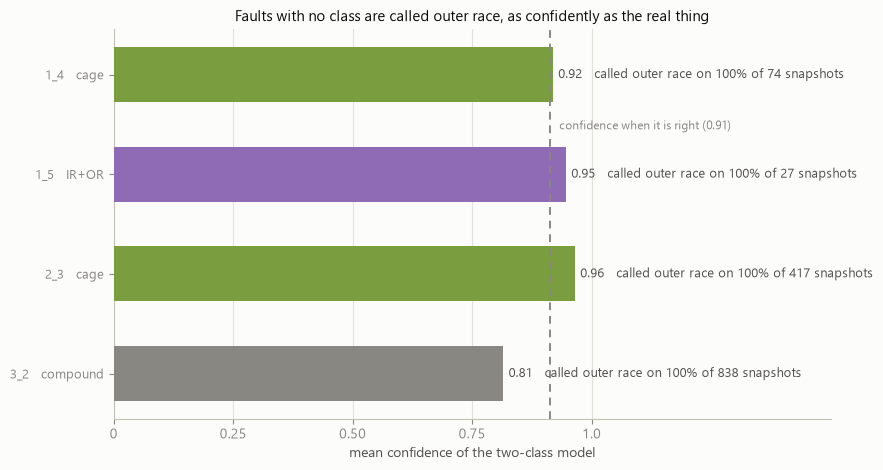

,truth,snapshots,called_OR,conf
Bearing,,,,
Bearing1_4,cage,74,100%,0.92
Bearing1_5,IR+OR,27,100%,0.95
Bearing2_3,cage,417,100%,0.96
Bearing3_2,compound,838,100%,0.81


In [5]:
full = RandomForestClassifier(**RF).fit(
    np.vstack([DELTA[o][ALARM[o]:] for o in RACE]),
    np.concatenate([[FAULT[o]] * (N[o] - ALARM[o]) for o in RACE]))

rows = []
for b in OTHER:
    prob = full.predict_proba(DELTA[b][ALARM[b]:])
    lab = full.classes_[prob.argmax(axis=1)]
    rows.append(dict(Bearing=b, truth=FAULT[b], snapshots=len(lab),
                     called_OR=(lab == "OR").mean(), conf=prob.max(axis=1).mean()))
oos = pd.DataFrame(rows).set_index("Bearing")

# the same confidence, on units the model does have a class for
in_conf = []
for held in RACE:
    tr = [o for o in RACE if o != held]
    m = RandomForestClassifier(**RF).fit(
        np.vstack([DELTA[o][ALARM[o]:] for o in tr]),
        np.concatenate([[FAULT[o]] * (N[o] - ALARM[o]) for o in tr]))
    in_conf.append(m.predict_proba(DELTA[held][ALARM[held]:]).max(axis=1).mean())
in_conf = float(np.mean(in_conf))

fig, ax = plt.subplots(figsize=(9.0, 4.8))
ys = np.arange(len(oos))
for i, (b, r) in enumerate(oos.iterrows()):
    ax.barh(i, r["conf"], height=0.55, color=FCOLOR[r["truth"]], zorder=3)
    ax.text(r["conf"] + 0.012, i, f'{r["conf"]:.2f}   called outer race on '
            f'{r["called_OR"]:.0%} of {int(r["snapshots"])} snapshots',
            va="center", fontsize=9, color=INK2)
ax.axvline(in_conf, color=MUTED, lw=1.4, ls=(0, (4, 3)), zorder=4)
ax.text(in_conf + 0.02, 0.52, f"confidence when it is right ({in_conf:.2f})",
        fontsize=8.5, color=MUTED, ha="left", va="center")
ax.set_yticks(ys, [f'{b.replace("Bearing", "")}   {oos.loc[b, "truth"]}' for b in oos.index],
              fontsize=9.5)
ax.invert_yaxis()
ax.set_xlim(0, 1.5)
ax.set_xticks([0, .25, .5, .75, 1.0], ["0", "0.25", "0.50", "0.75", "1.0"])
ax.set_xlabel("mean confidence of the two-class model")
ax.grid(axis="y", visible=False)
ax.set_title("Faults with no class are called outer race, as confidently as the real thing",
             fontsize=11)
plt.tight_layout()
plt.show()

oos.style.format({"called_OR": "{:.0%}", "conf": "{:.2f}"})

**Every one of the four is called "outer race", and the model is as confident
doing it as when it is right.** Mean confidence on the out-of-scope units runs
0.81 to 0.96, against 0.91 on held-out units it genuinely has a class for.
There is no confidence signal to gate on: a cage failure and a real outer-race
failure look equally certain from the outside.

That is a worse failure than being wrong. Notebook 12's KA30 gate assumed model
confidence carried information about when to distrust the answer; here it
carries none, and an explanation layer built on top would produce a fluent,
well-evidenced, confidently wrong account of an outer-race defect for a bearing
whose cage has broken. For a maintenance system that has to explain its
diagnoses, that is the most dangerous behaviour available.

It also settles the open scope question in the direction of doing more work
rather than less. Two options remain, and they are not equivalent:

1. **Add the classes.** Two cage units and one compound unit is far too thin to
   train on — the learning curve above says two units of a class gets nowhere
   near the ceiling — so this needs data the project does not have.
2. **Add a reject option.** Train the two-class model as now, but require
   positive evidence for the class it calls rather than a relative preference —
   a distance-to-training-distribution test, or a one-class model per race.
   That is achievable with what is here.

Option 2 is the honest near-term answer, and it changes the deliverable from
"which race" to "which race, or *I don't recognise this*". The second is a
better input to an explanation than a confident mislabel.

## Does attribution get easier as the fault grows?

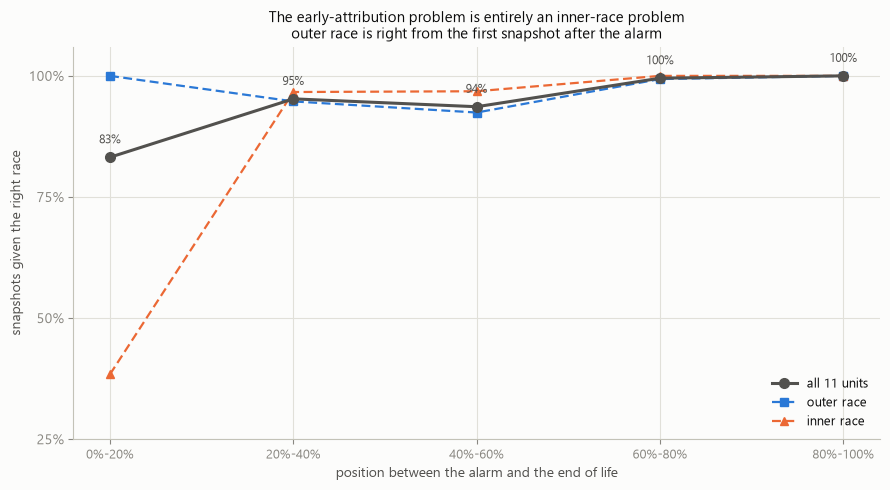

,all,outer race,inner race
0%-20%,0.832,1.000,0.384
20%-40%,0.953,0.947,0.967
40%-60%,0.936,0.924,0.968
60%-80%,0.995,0.993,1.000
80%-100%,1.000,1.000,1.000


In [6]:
BINS = [(0.0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
prog = {f"{a:.0%}-{b_:.0%}": {"OR": [], "IR": []} for a, b_ in BINS}
for held in RACE:
    tr = [o for o in RACE if o != held]
    m = RandomForestClassifier(**RF).fit(
        np.vstack([DELTA[o][ALARM[o]:] for o in tr]),
        np.concatenate([[FAULT[o]] * (N[o] - ALARM[o]) for o in tr]))
    ok = m.predict(DELTA[held][ALARM[held]:]) == FAULT[held]
    frac = np.linspace(0, 1, len(ok), endpoint=False)
    for a, b_ in BINS:
        sel = (frac >= a) & (frac < b_)
        if sel.any():
            prog[f"{a:.0%}-{b_:.0%}"][FAULT[held]].append(ok[sel].mean())

lab = list(prog)
allv = [np.mean(prog[k]["OR"] + prog[k]["IR"]) for k in lab]
orv = [np.mean(prog[k]["OR"]) for k in lab]
irv = [np.mean(prog[k]["IR"]) for k in lab]

fig, ax = plt.subplots(figsize=(9.0, 5.0))
x = np.arange(len(lab))
ax.plot(x, allv, color=INK2, lw=2.2, marker="o", ms=7, zorder=4, label="all 11 units")
ax.plot(x, orv, color=C_BLUE, lw=1.6, marker="s", ms=6, ls=(0, (4, 2)), zorder=3,
        label="outer race")
ax.plot(x, irv, color=C_ORANGE, lw=1.6, marker="^", ms=6, ls=(0, (4, 2)), zorder=3,
        label="inner race")
for xi, v in zip(x, allv):
    ax.annotate(f"{v:.0%}", (xi, v), textcoords="offset points", xytext=(0, 10),
                fontsize=8.5, color=INK2, ha="center")
ax.set_xticks(x, lab, fontsize=9.5)
ax.set_ylim(0.25, 1.06)
ax.set_yticks([.25, .5, .75, 1.0], ["25%", "50%", "75%", "100%"])
ax.set_xlabel("position between the alarm and the end of life")
ax.set_ylabel("snapshots given the right race")
ax.legend(fontsize=9, loc="lower right")
ax.set_title("The early-attribution problem is entirely an inner-race problem\n"
             "outer race is right from the first snapshot after the alarm", fontsize=11)
plt.tight_layout()
plt.show()

pd.DataFrame({"all": allv, "outer race": orv, "inner race": irv}, index=lab).round(3)

The aggregate looks like a gentle ramp — 83 % of snapshots right in the first
fifth after the alarm, 100 % in the last — but splitting it by race shows the
average is hiding two completely different behaviours.

**Outer-race faults are called correctly from the very first snapshot after the
alarm: 100 %, with no ramp at all.** The entire early-attribution problem
belongs to the inner race, which scores **38.4 %** in that first fifth and then
jumps to 96.7 % in the second.

Below 50 % on a two-class problem is worse than a coin toss, and it is not
noise: an inner-race fault that has just been detected is **actively
mislabelled as outer race**. The direction matters. Combined with the previous
two figures, the failure mode is specific — a freshly alarmed inner-race
bearing is the one case where this system produces a confident, wrong,
actionable diagnosis, and inner-race faults are also the ones detected latest
(9.2 % of life remaining, notebook 13). The two weaknesses compound on the same
units.

It also explains the naming gap in the previous figure without a separate
mechanism: Bearing3_5's race is unstable early not because the alarm was wrong
but because the fault had not yet written enough structure into the envelope.

## What this changes

1. **The split works, and it is worth making.** Stage 1 (RMS + kurtosis on the
   unit's own baseline) alarms with 58.7 % of life remaining at 4.2 % false
   alarms; stage 2 (envelope order bands) then calls **11 of 11** races
   correctly, 94.1 % of post-alarm snapshots. Neither family does both jobs
   well, which is why notebook 13's finding 5 was a signpost rather than a
   defeat.
2. **The sim-to-real cost for attribution is now measured**: 87.3 % from
   artificial damage (notebook 11, Paderborn) against 94.1 % from real damaged
   units, same feature family, same leave-one-bearing-out discipline.
3. **Real damaged units are priced at about six** — four of the majority class
   and **two of the minority**. One unit of each is *worse* than a
   well-populated artificial set (81.8 %), so the requirement is a small fleet,
   not a token sample. This turns notebook 11's "hard requirement" into a
   number.
4. **Naming lags alarming, and unevenly**: outer race is named 9 points of life
   after it is found, inner race is barely found at all (9.2 % of life
   remaining). Any recommendation that needs the fault element must be
   scheduled against a different clock than one that needs only an alarm.
5. **The model has no way to say "I don't know".** Cage, compound and combined
   faults are all called outer race at 0.81–0.96 confidence, against 0.91 when
   it is right. Confidence carries no signal about being out of scope.
6. **The early-attribution failure is entirely inner-race.** Outer race is
   100 % correct from the first snapshot after the alarm; inner race is 38.4 %
   — below chance, and mislabelled as outer race — before recovering to 96.7 %.
   Inner-race faults are therefore detected latest *and* diagnosed wrongly
   first, on the same units.